# 02 · Busca: recall@1, recall@3 e limiar

Guiding Hand · Generative AI for Engineering

Objetivo: medir se a busca encontra o trecho certo (**recall@1** e **recall@3**) e escolher um **limiar de similaridade** para decidir quando o sistema deve responder "não consta" sem nem chamar o modelo.

Rodar com `Run All`. Na primeira vez baixa o modelo de embeddings (~470 MB).

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))
import numpy as np, pandas as pd
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 80)
from config import CASOS, LIMIAR_JSON, RESULTADOS, TOP_K
from busca import Buscador

b = Buscador()
casos = [json.loads(l) for l in open(CASOS, encoding='utf-8')]
print(len(b.trechos), 'trechos |', len(casos), 'casos')

W1110 21:52:36.585000 11228 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
W1110 21:52:41.379000 11228 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

c:\Users\auada\Downloads\guiding-hand-genai\guiding-hand-genai\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\auada\.cache\huggingface\hub\models--intfloat--multilingual-e5-small. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

... (8 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

32 trechos | 35 casos


## 1. Recall@1 e recall@3
Só os 27 casos com resposta entram (os 8 "não consta" não têm trecho esperado). Acerto@k = o trecho do gabarito está entre os k mais parecidos.

In [2]:
linhas = []
for c in casos:
    achados = b.buscar(c['pergunta'], k=TOP_K)
    ids = [t['id'] for t, _ in achados]
    e = c['tipo'] == 'resposta'
    linhas.append({'id': c['id'], 'tipo': c['tipo'], 'esperado': c['trecho_esperado'], 'top3': ids,
                   'score_top1': round(achados[0][1], 4),
                   'acerto@1': (c['trecho_esperado'] == ids[0]) if e else None,
                   'acerto@3': (c['trecho_esperado'] in ids) if e else None})
df = pd.DataFrame(linhas)
resp = df[df.tipo == 'resposta']
recall1, recall3 = float(resp['acerto@1'].mean()), float(resp['acerto@3'].mean())
print(f"recall@1 = {recall1:.3f}  ({int(resp['acerto@1'].sum())}/{len(resp)})")
print(f"recall@3 = {recall3:.3f}  ({int(resp['acerto@3'].sum())}/{len(resp)})")

recall@1 = 0.815  (22/27)
recall@3 = 0.963  (26/27)


### Casos em que o trecho certo não veio em 1º lugar

In [3]:
erros = resp[resp['acerto@1'] == False][['id', 'esperado', 'top3', 'score_top1']]
print(erros.to_string(index=False) if len(erros) else 'Nenhum: recall@1 = 100%')

 id esperado            top3  score_top1
Q02      T02 [T17, T11, T21]      0.9024
Q03      T03 [T21, T03, T17]      0.8834
Q08      T08 [T07, T26, T08]      0.9084
Q11      T12 [T14, T12, T31]      0.8925
Q19      T22 [T05, T22, T01]      0.9056


## 2. Limiar de similaridade
A similaridade do melhor trecho (`score_top1`) tende a ser **maior** quando a base tem a resposta e **menor** quando não tem. Testamos vários limiares: abaixo do limiar o sistema recusa; acima, segue para o modelo.

- *aceita respondíveis*: % dos 27 casos com resposta que passam do limiar (quanto maior, melhor)
- *recusa não consta*: % dos 8 casos sem resposta que ficam abaixo do limiar (quanto maior, melhor)
- Critério: maximizar a média das duas (acurácia balanceada). Em empate, usamos o meio do intervalo.

In [4]:
pos = df[df.tipo == 'resposta'].score_top1.values
neg = df[df.tipo == 'nao_consta'].score_top1.values
print(f'respondíveis: min={pos.min():.3f} média={pos.mean():.3f} máx={pos.max():.3f}')
print(f'não consta:   min={neg.min():.3f} média={neg.mean():.3f} máx={neg.max():.3f}')

cand = np.round(np.arange(min(pos.min(), neg.min()) - 0.005, max(pos.max(), neg.max()) + 0.005, 0.0025), 4)
tab = pd.DataFrame([{'limiar': t, 'aceita respondíveis': (pos >= t).mean(),
                     'recusa não consta': (neg < t).mean(),
                     'balanceada': ((pos >= t).mean() + (neg < t).mean()) / 2} for t in cand])
melhor = tab.balanceada.max()
plato = tab[tab.balanceada >= melhor - 1e-9]
limiar = round(float(plato.limiar.median()), 4)
print(f'\nmelhor balanceada = {melhor:.3f} para limiares de {plato.limiar.min()} a {plato.limiar.max()}')
print(f'LIMIAR ESCOLHIDO = {limiar}')
print()
print(tab.iloc[::4].round(3).to_string(index=False))

respondíveis: min=0.848 média=0.903 máx=0.926
não consta:   min=0.798 média=0.845 máx=0.873

melhor balanceada = 0.981 para limiares de 0.8754 a 0.8754
LIMIAR ESCOLHIDO = 0.8754

 limiar  aceita respondíveis  recusa não consta  balanceada
  0.793                1.000              0.000       0.500
  0.803                1.000              0.125       0.562
  0.813                1.000              0.250       0.625
  0.823                1.000              0.250       0.625
  0.833                1.000              0.250       0.625
  0.843                1.000              0.375       0.688
  0.853                0.963              0.500       0.731
  0.863                0.963              0.625       0.794
  0.873                0.963              0.875       0.919
  0.883                0.926              1.000       0.963
  0.893                0.704              1.000       0.852
  0.903                0.444              1.000       0.722
  0.913                0.333             

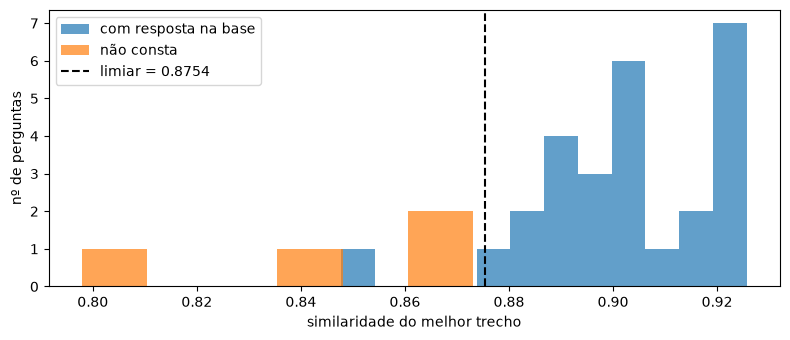

In [5]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 3.5))
plt.hist(pos, bins=12, alpha=.7, label='com resposta na base')
plt.hist(neg, bins=12, alpha=.7, label='não consta')
plt.axvline(limiar, color='k', ls='--', label=f'limiar = {limiar}')
plt.xlabel('similaridade do melhor trecho'); plt.ylabel('nº de perguntas'); plt.legend(); plt.tight_layout()
(Path.cwd().parent / 'avaliacao' / 'figuras').mkdir(exist_ok=True)
plt.savefig(Path.cwd().parent / 'avaliacao' / 'figuras' / 'limiar.png', dpi=150)
plt.show()

In [6]:
LIMIAR_JSON.write_text(json.dumps({'limiar': limiar, 'recall@1': round(recall1, 3), 'recall@3': round(recall3, 3),
    'aceita_respondiveis': round(float((pos >= limiar).mean()), 3),
    'recusa_nao_consta': round(float((neg < limiar).mean()), 3),
    'modelo_embedding': 'intfloat/multilingual-e5-small'}, indent=2), encoding='utf-8')
print(LIMIAR_JSON.read_text(encoding='utf-8'))

{
  "limiar": 0.8754,
  "recall@1": 0.815,
  "recall@3": 0.963,
  "aceita_respondiveis": 0.963,
  "recusa_nao_consta": 1.0,
  "modelo_embedding": "intfloat/multilingual-e5-small"
}


## 3. Interpretação 

Recall@1 de 81,5% e recall@3 de 96,3% mostram que o trecho certo quase sempre está entre os três primeiros. Os cinco erros de recall@1 vêm de trechos com conteúdo vizinho (ex.: acessibilidade no art. 3º e no art. 53). O limiar de 0,8754 recusa 100% dos “não consta” e aceita 96,3% das perguntas respondíveis. Acima disso a taxa de aceitação cai rápido (70% em 0,893). A margem é estreita (o maior “não consta” tem 0,873), e o limiar foi escolhido nos mesmos casos em que é medido, então o resultado tende a ser otimista.